<a href="https://colab.research.google.com/github/AmalKhairalla/OPL-Insights/blob/main/DS330_OpenPowerlifting_Exploratory_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!wget -c -O /content/openpowerlifting-new.zip https://openpowerlifting.gitlab.io/opl-csv/files/openpowerlifting-latest.zip


--2026-11-18 22:58:58--  https://openpowerlifting.gitlab.io/opl-csv/files/openpowerlifting-latest.zip
Resolving openpowerlifting.gitlab.io (openpowerlifting.gitlab.io)... 35.185.44.232, 2600:1901:0:7b8a::
Connecting to openpowerlifting.gitlab.io (openpowerlifting.gitlab.io)|35.185.44.232|:443... connected.
HTTP request sent, awaiting response... 416 Requested Range Not Satisfiable

    The file is already fully retrieved; nothing to do.



In [2]:

import subprocess

result = subprocess.run(
    ["unzip", "-t", "/content/openpowerlifting-new.zip"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-500:])
print(result.stderr[-500:])


Return code: 0
Archive:  /content/openpowerlifting-new.zip
    testing: openpowerlifting-2026-11-14/   OK
    testing: openpowerlifting-2026-11-14/README.txt   OK
    testing: openpowerlifting-2026-11-14/openpowerlifting-2026-11-14-6b8787a8.csv   OK
    testing: openpowerlifting-2026-11-14/LICENSE.txt   OK
No errors detected in compressed data of /content/openpowerlifting-new.zip.




In [3]:

import pandas as pd
import zipfile

zip_path = "/content/openpowerlifting-new.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    csv_name = next(
        name for name in z.namelist()
        if name.endswith(".csv")
    )

    with z.open(csv_name) as f:
        df_sample = pd.read_csv(f, nrows=1000)

print("Shape:", df_sample.shape)
display(df_sample.head())


Shape: (1000, 42)


,Name,Sex,Event,Equipment,Age,AgeClass,BirthYearClass,Division,BodyweightKg,WeightClassKg,...,Country,State,Federation,ParentFederation,Date,MeetCountry,MeetState,MeetTown,MeetName,Sanctioned
0,Bill Gillespie,M,BD,Unlimited,59.0,55-59,NaN,Open,146.6,140+,...,USA,NaN,AmericanSA,NaN,2018-10-12,USA,VA,Lynchburg,DT Liberty Fall Classic,Yes
1,Andre Mealy,M,B,Raw,24.0,24-34,24-39,Open,123.8,125,...,USA,NaN,AmericanSA,NaN,2018-10-12,USA,VA,Lynchburg,DT Liberty Fall Classic,Yes
2,David Lambauch,M,SBD,Raw,NaN,NaN,NaN,Open,88.1,90,...,USA,NaN,AmericanSA,NaN,2018-12-05,USA,VA,Lynchburg,DT Liberty Christmas Classic,Yes
3,Jeff Boschman,M,D,Raw,26.0,24-34,24-39,Open,108.9,110,...,USA,NaN,AmericanSA,NaN,2018-12-05,USA,VA,Lynchburg,DT Liberty Christmas Classic,Yes
4,Ben Williamson,M,D,Raw,NaN,NaN,NaN,Open,121.3,125,...,USA,NaN,AmericanSA,NaN,2018-12-05,USA,VA,Lynchburg,DT Liberty Christmas Classic,Yes


In [4]:

from collections import Counter
import pandas as pd
import zipfile

counts = Counter()

columns = [
    "Federation",
    "Equipment",
    "Event",
    "Best3SquatKg",
    "Best3BenchKg",
    "Best3DeadliftKg"
]

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(csv_name) as f:

        for chunk in pd.read_csv(
            f,
            usecols=columns,
            chunksize=100_000
        ):
            # Keep competitions containing all 3 lifts
            chunk = chunk[chunk["Event"] == "SBD"]

            # Keep successful results for all lifts
            lifts = [
                "Best3SquatKg",
                "Best3BenchKg",
                "Best3DeadliftKg"
            ]

            chunk = chunk[
                chunk[lifts].notna().all(axis=1)
                & chunk[lifts].gt(0).all(axis=1)
            ]

            # Count records by federation and equipment
            group_counts = chunk.groupby(
                ["Federation", "Equipment"]
            ).size()

            counts.update(group_counts.to_dict())

results = pd.Series(counts).rename(
    "Records"
).reset_index()

results.columns = [
    "Federation", "Equipment", "Records"
]

display(
    results.sort_values(
        "Records", ascending=False
    ).head(30)
)


,Federation,Equipment,Records
492,THSPA,Single-ply,326455
444,USAPL,Raw,256632
993,USPA,Raw,142054
1015,THSWPA,Unlimited,139387
1014,THSWPA,Single-ply,138492
493,THSPA,Unlimited,129963
694,USPF,Single-ply,110677
178,FPR,Single-ply,81984
445,USAPL,Single-ply,59544
711,CPU,Raw,43394


In [5]:

# Compare equipment categories within federations

equipment_table = results.pivot_table(
    index="Federation",
    columns="Equipment",
    values="Records",
    aggfunc="sum",
    fill_value=0
)

# Total records per federation
equipment_table["Total"] = equipment_table.sum(axis=1)

# Sort from largest to smallest
equipment_table = equipment_table.sort_values(
    "Total", ascending=False
)

display(equipment_table.head(25))


Equipment,Multi-ply,Raw,Single-ply,Straps,Unlimited,Wraps,Total
Federation,,,,,,,
THSPA,0,6063,326455,0,129963,0,462481
USAPL,0,256632,59544,0,0,667,316843
THSWPA,0,5637,138492,0,139387,0,283516
USPA,650,142054,3577,0,72,24698,171051
FPR,0,36823,81984,0,0,31,118838
USPF,24,617,110677,0,0,178,111496
CPU,0,43394,10777,0,0,0,54171
APF,14484,11777,5008,0,1,9443,40713
EPA,0,36657,1549,0,0,1,38207


In [9]:

import pandas as pd
import zipfile

zip_path = "/content/openpowerlifting-new.zip"

year_counts = []

with zipfile.ZipFile(zip_path, "r") as z:
    csv_name = next(
        name for name in z.namelist()
        if name.endswith(".csv")
    )

    with z.open(csv_name) as f:
        for chunk in pd.read_csv(
            f,
            usecols=[
                "Federation", "Equipment", "Event",
                "Date", "Best3SquatKg",
                "Best3BenchKg", "Best3DeadliftKg"
            ],
            chunksize=100_000
        ):
            chunk = chunk[
                (chunk["Federation"] == "THSWPA") &
                (chunk["Event"] == "SBD")
            ].copy()

            lifts = [
                "Best3SquatKg",
                "Best3BenchKg",
                "Best3DeadliftKg"
            ]

            chunk = chunk[
                chunk[lifts].notna().all(axis=1) &
                chunk[lifts].gt(0).all(axis=1)
            ].copy()

            chunk["Year"] = pd.to_datetime(
                chunk["Date"], errors="coerce"
            ).dt.year

            year_counts.append(
                chunk.groupby(
                    ["Year", "Equipment"]
                ).size()
            )

year_table = (
    pd.concat(year_counts, axis=1)
    .fillna(0)
    .sum(axis=1)
    .unstack(fill_value=0)
    .astype(int)
)

display(year_table.tail(15))


Equipment,Raw,Single-ply,Unlimited
Year,,,
2012,0,247,0
2013,0,223,0
2014,0,14373,0
2015,0,16389,0
2016,0,17172,0
2017,0,17873,0
2018,0,18530,0
2019,0,19429,0
2020,0,20265,0


In [10]:
import pandas as pd
import zipfile

zip_path = "/content/openpowerlifting-new.zip"

year_counts = []

with zipfile.ZipFile(zip_path, "r") as z:
    csv_name = next(
        name for name in z.namelist()
        if name.endswith(".csv")
    )

    with z.open(csv_name) as f:
        for chunk in pd.read_csv(
            f,
            usecols=[
                "Federation", "Equipment", "Event",
                "Date", "Best3SquatKg",
                "Best3BenchKg", "Best3DeadliftKg"
            ],
            chunksize=100_000
        ):
            chunk = chunk[
                (chunk["Federation"] == "APF") &
                (chunk["Event"] == "SBD")
            ].copy()

            lifts = [
                "Best3SquatKg",
                "Best3BenchKg",
                "Best3DeadliftKg"
            ]

            chunk = chunk[
                chunk[lifts].notna().all(axis=1) &
                chunk[lifts].gt(0).all(axis=1)
            ].copy()

            chunk["Year"] = pd.to_datetime(
                chunk["Date"], errors="coerce"
            ).dt.year

            year_counts.append(
                chunk.groupby(
                    ["Year", "Equipment"]
                ).size()
            )

year_table = (
    pd.concat(year_counts, axis=1)
    .fillna(0)
    .sum(axis=1)
    .unstack(fill_value=0)
    .astype(int)
)

display(year_table.tail(15))


Equipment,Multi-ply,Raw,Single-ply,Unlimited,Wraps
Year,,,,,
2012,454,526,183,0,7
2013,642,956,19,0,16
2014,342,993,161,0,12
2015,345,1267,169,0,293
2016,198,973,211,0,626
2017,219,745,67,0,944
2018,296,740,63,0,1057
2019,296,672,113,0,1097
2020,184,397,61,0,570


In [11]:

import pandas as pd
import zipfile

zip_path = "/content/openpowerlifting-new.zip"

columns = [
    "Federation", "Equipment", "Event", "Date",
    "Sex", "Age", "BodyweightKg",
    "Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg"
]

lifts = [
    "Best3SquatKg",
    "Best3BenchKg",
    "Best3DeadliftKg"
]

apf_chunks = []

with zipfile.ZipFile(zip_path) as z:
    csv_name = next(
        name for name in z.namelist()
        if name.endswith(".csv")
    )

    with z.open(csv_name) as f:
        for chunk in pd.read_csv(
            f,
            usecols=columns,
            chunksize=100_000
        ):
            # APF only, SBD competition
            chunk = chunk[
                (chunk["Federation"] == "APF") &
                (chunk["Event"] == "SBD")
            ].copy()

            chunk["Year"] = pd.to_datetime(
                chunk["Date"], errors="coerce"
            ).dt.year

            # Compare the same time period
            chunk = chunk[
                chunk["Year"].between(2015, 2023)
            ]

            # Remove invalid/missing lifting results
            chunk = chunk.dropna(subset=lifts)

            chunk = chunk[
                chunk[lifts].gt(0).all(axis=1)
            ]

            apf_chunks.append(chunk)

apf = pd.concat(apf_chunks, ignore_index=True)

print("APF dataset shape:", apf.shape)

display(apf["Equipment"].value_counts())


APF dataset shape: (18890, 11)


,count
Equipment,
Wraps,8324
Raw,7049
Multi-ply,2508
Single-ply,1009


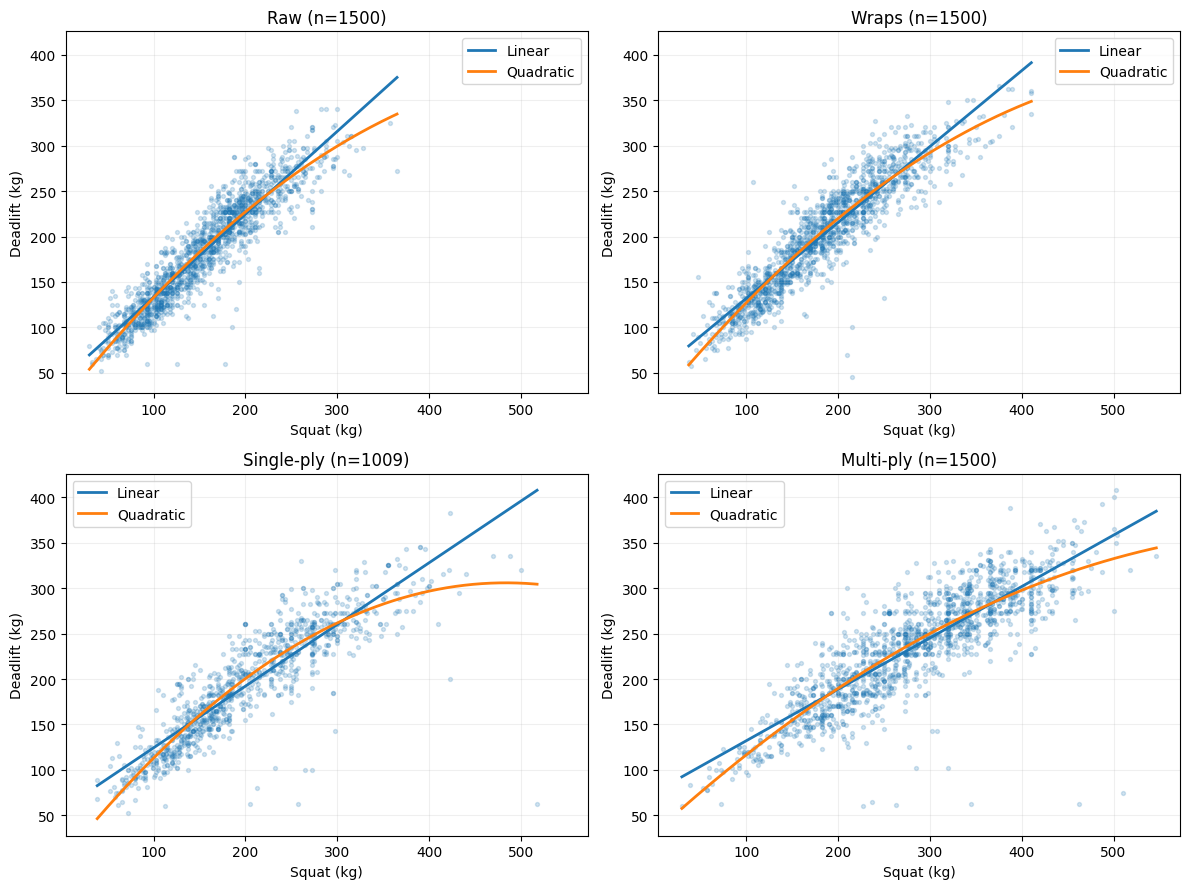

In [12]:

import numpy as np
import matplotlib.pyplot as plt

categories = ["Raw", "Wraps", "Single-ply", "Multi-ply"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, category in zip(axes.flat, categories):

    group = apf[
        apf["Equipment"] == category
    ].sample(
        n=min(1500, (apf["Equipment"] == category).sum()),
        random_state=42
    )

    x = group["Best3SquatKg"].to_numpy()
    y = group["Best3DeadliftKg"].to_numpy()

    # Straight line
    linear = np.polyfit(x, y, 1)

    # Quadratic curve
    quadratic = np.polyfit(x, y, 2)

    x_line = np.linspace(x.min(), x.max(), 200)

    ax.scatter(x, y, s=8, alpha=0.2)
    ax.plot(
        x_line, np.polyval(linear, x_line),
        label="Linear", linewidth=2
    )
    ax.plot(
        x_line, np.polyval(quadratic, x_line),
        label="Quadratic", linewidth=2
    )

    ax.set_title(f"{category} (n={len(group)})")
    ax.set_xlabel("Squat (kg)")
    ax.set_ylabel("Deadlift (kg)")
    ax.legend()
    ax.grid(alpha=0.2)

# Keep the same scales across all graphs
x_limits = [ax.get_xlim() for ax in axes.flat]
y_limits = [ax.get_ylim() for ax in axes.flat]

xmin = min(v[0] for v in x_limits)
xmax = max(v[1] for v in x_limits)
ymin = min(v[0] for v in y_limits)
ymax = max(v[1] for v in y_limits)

for ax in axes.flat:
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

plt.tight_layout()
plt.show()


In [13]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler, PolynomialFeatures
)
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

features = [
    "Age",
    "BodyweightKg",
    "Best3SquatKg",
    "Best3BenchKg"
]

target = "Best3DeadliftKg"

results_nonlinearity = []

for category in [
    "Raw", "Wraps", "Single-ply", "Multi-ply"
]:
    # Select and clean the category
    data = apf[
        apf["Equipment"] == category
    ].dropna(subset=features + [target]).copy()

    data = data[data["BodyweightKg"] > 0]

    # Equal samples for fair comparison
    n = min(800, len(data))

    if n < 100:
        continue

    data = data.sample(n=n, random_state=42)

    X = data[features]
    y = data[target]

    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.25, random_state=42
    )

    # Linear regression
    linear_model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    )

    linear_model.fit(X_train, y_train)

    linear_mse = mean_squared_error(
        y_val, linear_model.predict(X_val)
    )

    # Polynomial regression (degree 2)
    nonlinear_model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(
            degree=2, include_bias=False
        ),
        Ridge(alpha=1.0)
    )

    nonlinear_model.fit(X_train, y_train)

    nonlinear_mse = mean_squared_error(
        y_val, nonlinear_model.predict(X_val)
    )

    improvement = (
        (linear_mse - nonlinear_mse)
        / linear_mse * 100
    )

    results_nonlinearity.append({
        "Equipment": category,
        "Samples": n,
        "Linear MSE": round(linear_mse, 2),
        "Polynomial MSE": round(nonlinear_mse, 2),
        "Improvement (%)": round(improvement, 2)
    })

comparison = pd.DataFrame(results_nonlinearity)

display(comparison)


,Equipment,Samples,Linear MSE,Polynomial MSE,Improvement (%)
0,Raw,800,435.93,401.95,7.79
1,Wraps,800,433.41,405.05,6.54
2,Single-ply,787,611.85,489.14,20.06
3,Multi-ply,800,767.58,721.75,5.97


In [14]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

features = [
    "Age",
    "BodyweightKg",
    "Best3SquatKg",
    "Best3BenchKg"
]

target = "Best3DeadliftKg"

data = apf[
    apf["Equipment"] == "Single-ply"
].dropna(subset=features + [target]).copy()

data = data[
    data[features + [target]].gt(0).all(axis=1)
]

X = data[features]
y = data[target]

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

# Fit scalers ONLY on training data
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train)
X_val_scaled = x_scaler.transform(X_val)

y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

print("Training:", len(X_train))
print("Validation:", len(X_val))


Training: 590
Validation: 197


In [15]:

linear = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

polynomial = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    Ridge(alpha=1.0)
)

linear.fit(X_train, y_train)
polynomial.fit(X_train, y_train)

linear_mse = mean_squared_error(
    y_val, linear.predict(X_val)
)

poly_mse = mean_squared_error(
    y_val, polynomial.predict(X_val)
)

print("Linear MSE:", round(linear_mse, 2))
print("Polynomial MSE:", round(poly_mse, 2))


Linear MSE: 1025.91
Polynomial MSE: 1072.06


In [16]:

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import copy

torch.manual_seed(42)
np.random.seed(42)

Xtr = torch.tensor(X_train_scaled, dtype=torch.float32)
Xva = torch.tensor(X_val_scaled, dtype=torch.float32)

ytr = torch.tensor(y_train_scaled, dtype=torch.float32)

dataset = TensorDataset(Xtr, ytr)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

# Basic neural network
model = nn.Sequential(
    nn.Linear(4, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

loss_fn = nn.MSELoss()

train_losses = []
val_losses = []

best_val = float("inf")
best_weights = None
patience = 25
counter = 0

for epoch in range(200):

    model.train()

    for xb, yb in loader:
        optimizer.zero_grad()

        predictions = model(xb)
        loss = loss_fn(predictions, yb)

        loss.backward()
        optimizer.step()

    # Evaluate on original kg scale
    model.eval()
    with torch.no_grad():
        train_pred = model(Xtr).numpy()
        val_pred = model(Xva).numpy()

    train_pred_kg = y_scaler.inverse_transform(train_pred)
    val_pred_kg = y_scaler.inverse_transform(val_pred)

    train_mse = mean_squared_error(
        y_train, train_pred_kg.ravel()
    )

    val_mse = mean_squared_error(
        y_val, val_pred_kg.ravel()
    )

    train_losses.append(train_mse)
    val_losses.append(val_mse)

    if val_mse < best_val - 0.01:
        best_val = val_mse
        best_weights = copy.deepcopy(model.state_dict())
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping at epoch", epoch + 1)
        break

model.load_state_dict(best_weights)

print("Best Neural Network Validation MSE:",
      round(best_val, 2))


Early stopping at epoch 33
Best Neural Network Validation MSE: 930.07


,Model,Validation MSE,Improvement vs Linear (%)
0,Linear Regression,1025.91,0.00
1,Polynomial Regression,1072.06,-4.50
2,Neural Network,930.07,9.34


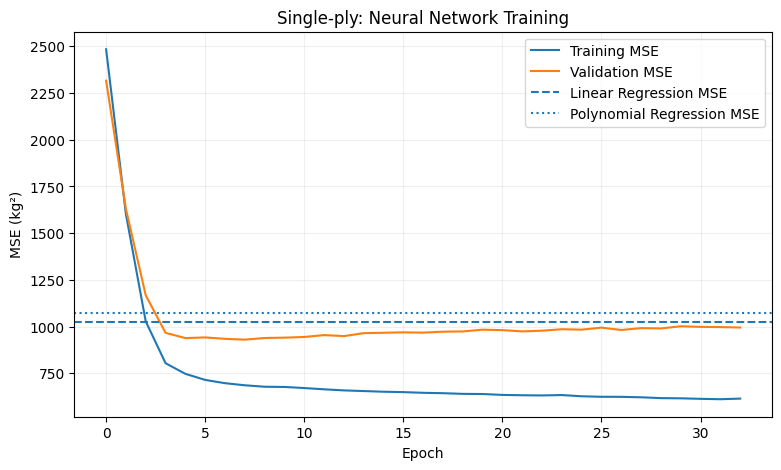

In [17]:

import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression",
        "Neural Network"
    ],
    "Validation MSE": [
        linear_mse,
        poly_mse,
        best_val
    ]
})

comparison["Improvement vs Linear (%)"] = (
    (linear_mse - comparison["Validation MSE"])
    / linear_mse * 100
)

display(comparison.round(2))

plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training MSE")
plt.plot(val_losses, label="Validation MSE")

plt.axhline(
    linear_mse,
    linestyle="--",
    label="Linear Regression MSE"
)

plt.axhline(
    poly_mse,
    linestyle=":",
    label="Polynomial Regression MSE"
)

plt.xlabel("Epoch")
plt.ylabel("MSE (kg²)")
plt.title("Single-ply: Neural Network Training")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


#single py

In [18]:

import pandas as pd
import zipfile

zip_path = "/content/openpowerlifting-new.zip"

columns = [
    "Federation", "Equipment", "Event",
    "Age", "BodyweightKg",
    "Best3SquatKg", "Best3BenchKg",
    "Best3DeadliftKg"
]

parts = []

with zipfile.ZipFile(zip_path) as z:
    csv_name = next(
        name for name in z.namelist()
        if name.endswith(".csv")
    )

    with z.open(csv_name) as f:
        for chunk in pd.read_csv(
            f,
            usecols=columns,
            chunksize=100_000
        ):
            selected = chunk[
                (chunk["Federation"] == "APF") &
                (chunk["Equipment"] == "Single-ply") &
                (chunk["Event"] == "SBD")
            ]

            parts.append(selected)

single_ply_all = pd.concat(
    parts, ignore_index=True
)

lifts = [
    "Best3SquatKg",
    "Best3BenchKg",
    "Best3DeadliftKg"
]

valid_lifts = single_ply_all[
    single_ply_all[lifts].notna().all(axis=1)
    & single_ply_all[lifts].gt(0).all(axis=1)
]

valid_bodyweight = valid_lifts[
    valid_lifts["BodyweightKg"].notna()
    & valid_lifts["BodyweightKg"].gt(0)
]

complete_age = valid_bodyweight[
    valid_bodyweight["Age"].notna()
    & valid_bodyweight["Age"].gt(0)
]

print("All APF Single-ply SBD:", len(single_ply_all))
print("Valid three lifts:", len(valid_lifts))
print("Valid lifts + bodyweight:", len(valid_bodyweight))
print("Also valid age:", len(complete_age))


All APF Single-ply SBD: 5479
Valid three lifts: 5008
Valid lifts + bodyweight: 4779
Also valid age: 2002


In [19]:

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
import copy

# Three features without age
features_3 = [
    "BodyweightKg",
    "Best3SquatKg",
    "Best3BenchKg"
]

# Four features including age
features_4 = ["Age"] + features_3

target = "Best3DeadliftKg"

# A: All valid records without age
data_A = valid_bodyweight.copy()

# B and C: Same records with valid age
data_BC = complete_age.copy()

# Ensure the same record IDs are retained
assert set(data_BC.index).issubset(set(data_A.index))

print("A - All records, no age:", len(data_A))
print("B - Complete records, with age:", len(data_BC))
print("C - Complete records, no age:", len(data_BC))


A - All records, no age: 4779
B - Complete records, with age: 2002
C - Complete records, no age: 2002


In [20]:

def compare_models(data, features, train_ids, val_ids, seed=42):

    X_train = data.loc[train_ids, features]
    X_val = data.loc[val_ids, features]
    y_train = data.loc[train_ids, target]
    y_val = data.loc[val_ids, target]

    # 1. Ordinary linear regression
    linear = make_pipeline(
        StandardScaler(),
        LinearRegression()
    )
    linear.fit(X_train, y_train)

    linear_mse = mean_squared_error(
        y_val, linear.predict(X_val)
    )

    # 2. Polynomial regression, degree 2
    polynomial = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        Ridge(alpha=1.0)
    )
    polynomial.fit(X_train, y_train)

    poly_mse = mean_squared_error(
        y_val, polynomial.predict(X_val)
    )

    # 3. PyTorch neural network
    torch.manual_seed(seed)

    x_scaler = StandardScaler()
    y_scaler = StandardScaler()

    Xtr = torch.tensor(
        x_scaler.fit_transform(X_train),
        dtype=torch.float32
    )
    Xva = torch.tensor(
        x_scaler.transform(X_val),
        dtype=torch.float32
    )

    ytr = torch.tensor(
        y_scaler.fit_transform(
            y_train.to_numpy().reshape(-1, 1)
        ),
        dtype=torch.float32
    )

    model = nn.Sequential(
        nn.Linear(len(features), 32),
        nn.ReLU(),
        nn.Linear(32, 16),
        nn.ReLU(),
        nn.Linear(16, 1)
    )

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )
    criterion = nn.MSELoss()

    loader = DataLoader(
        TensorDataset(Xtr, ytr),
        batch_size=32,
        shuffle=True
    )

    best_mse = float("inf")
    best_epoch = 0
    best_weights = None
    patience = 20
    counter = 0

    for epoch in range(150):
        model.train()

        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            pred_scaled = model(Xva).numpy()

        pred_kg = y_scaler.inverse_transform(
            pred_scaled
        ).ravel()

        val_mse = mean_squared_error(y_val, pred_kg)

        if val_mse < best_mse - 0.01:
            best_mse = val_mse
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            break

    model.load_state_dict(best_weights)

    return {
        "Linear MSE": linear_mse,
        "Polynomial MSE": poly_mse,
        "Neural MSE": best_mse,
        "Best NN Epoch": best_epoch
    }


In [21]:

# Split A: 4,779 records
train_A, val_A = train_test_split(
    data_A.index,
    test_size=0.20,
    random_state=42
)

# Shared split for B and C: 2,002 records
train_BC, val_BC = train_test_split(
    data_BC.index,
    test_size=0.20,
    random_state=42
)

results = {}

results["A: All, no Age"] = compare_models(
    data_A, features_3, train_A, val_A
)

results["B: Complete, with Age"] = compare_models(
    data_BC, features_4, train_BC, val_BC
)

results["C: Complete, no Age"] = compare_models(
    data_BC, features_3, train_BC, val_BC
)

results_df = pd.DataFrame(results).T

display(results_df.round(2))


,Linear MSE,Polynomial MSE,Neural MSE,Best NN Epoch
"A: All, no Age",1078.64,941.62,870.17,128.0
"B: Complete, with Age",836.83,758.64,750.38,16.0
"C: Complete, no Age",836.36,776.52,805.79,16.0


In [22]:

models = ["Linear MSE", "Polynomial MSE", "Neural MSE"]

age_effect = pd.DataFrame({
    "Model": models,
    "Without Age": results_df.loc[
        "C: Complete, no Age", models
    ].values,
    "With Age": results_df.loc[
        "B: Complete, with Age", models
    ].values
})

age_effect["Age Improvement (%)"] = (
    (age_effect["Without Age"] - age_effect["With Age"])
    / age_effect["Without Age"] * 100
)

display(age_effect.round(2))


,Model,Without Age,With Age,Age Improvement (%)
0,Linear MSE,836.36,836.83,-0.06
1,Polynomial MSE,776.52,758.64,2.30
2,Neural MSE,805.79,750.38,6.88


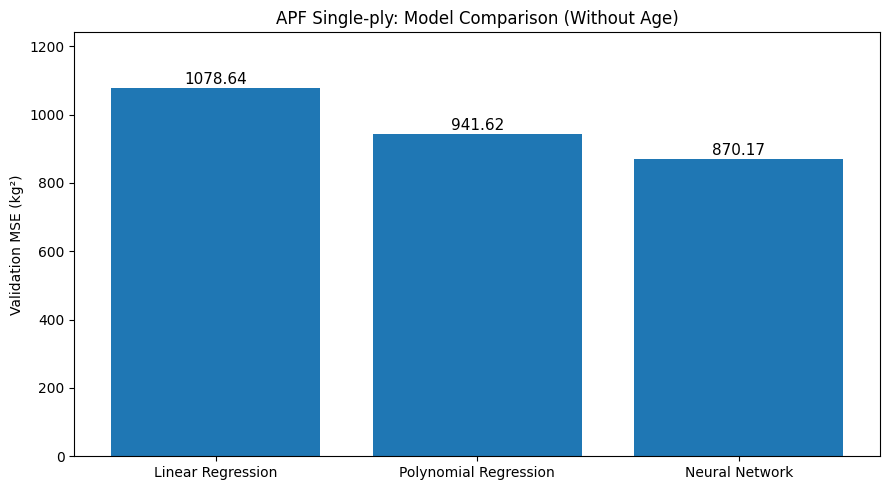

In [23]:

import matplotlib.pyplot as plt
import numpy as np

models = [
    "Linear Regression",
    "Polynomial Regression",
    "Neural Network"
]

mse = [1078.64, 941.62, 870.17]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(models, mse)

for bar, value in zip(bars, mse):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 12,
        f"{value:.2f}",
        ha="center",
        fontsize=11
    )

ax.set_ylabel("Validation MSE (kg²)")
ax.set_title(
    "APF Single-ply: Model Comparison (Without Age)"
)

ax.set_ylim(0, max(mse) * 1.15)

plt.tight_layout()
plt.show()
